NAME: Anna Bernardi

DATE: September 2025

This notebook will contain a function for performing predictions with Local Regression (LOESS) using one predictor

## Code Requirements 

In [5]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

## Loading the data
The data provided is contained in the file `pollution_cleaneddata.csv`, that's going to get loaded into a pandas DataFrame 

In [6]:
df = pd.read_csv('pollution_cleaneddata.csv')
df.head()


,PREC,JANT,JULT,OVR65,POPN,EDUC,HOUS,DENS,NONW,WWDRK,POOR,HC,NOX,SO@,HUMID,MORT
0,36.0,27.0,71.0,8.1,3.34,11.4,81.5,3243.0,8.8,42.6,11.7,21.0,15.0,59.0,59.0,921.870
1,35.0,23.0,72.0,11.1,3.14,11.0,78.8,4281.0,3.5,50.7,14.4,8.0,10.0,39.0,57.0,997.875
2,44.0,29.0,74.0,10.4,3.21,9.8,81.6,4260.0,0.8,39.4,12.4,6.0,6.0,33.0,54.0,962.354
3,47.0,45.0,79.0,6.5,3.41,11.1,77.5,3125.0,27.1,50.2,20.6,18.0,8.0,24.0,56.0,982.291
4,43.0,35.0,77.0,7.6,3.44,9.6,84.6,6441.0,24.4,43.7,14.3,43.0,38.0,206.0,55.0,1071.289


We're insterested in predicting the total age-adjusted mortality rate per 100,000 for an area with 10, 18 and 25% of families with income < $3000

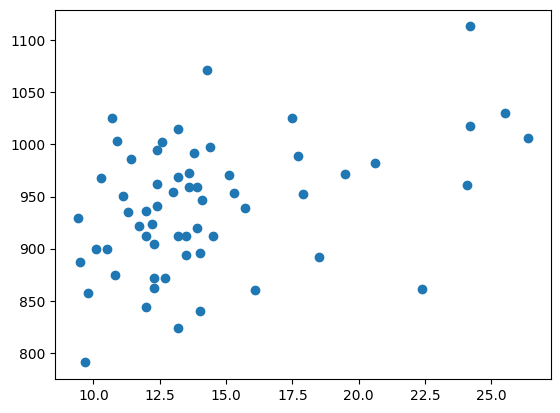

In [ ]:
y_obs = np.array(df.MORT) #total age-adjusted mortality rate per 100'000
x_obs = np.array(df.POOR) #% of families with income < $3000

x0 = np.array([10,18,25])

plt.scatter(x_obs,y_obs)

## Function for performing predictions with local regression
We'll first define a function to get the indeces of the nearest k-neighbours to the given x0 points

In [9]:
def near_neighbours(x,x0,k):
    """The function finds the indeces of the nearest k-th neighbours to x0

    INPUT
    x : array (or list) of observations of the response variable
    x0: array (or list) of predictor values at which to make predictions 
    k : number of neighbours

    OUTPUT 
    array of the indices of the k nearest neighbours to x0
    """
    distances = np.abs(x0-x)
    return np.argsort(distances)[:k]


In this notebook the inverse of the distances are going to get used as the weights for LOESS, even though for a smoother decrease of the weights with the distance it would be better to use a kernel (like the tri-cube function or Guassian)

The estimated parameters are derived from minimizing:

$Q(\beta) = \sum_{i=1}^{k} K_{i0}(yi - \beta_0 - \beta_1x_i)^2$

This is done by finding the parameters for which the derivative $\frac{\partial Q(\beta)}{\partial \beta} = 0 $

The [solution](https://en.wikipedia.org/wiki/Weighted_least_squares#Solution) is given by the following : 
$$ \hat\beta = (X^T W X)^{-1} X^T W y $$
where:
* X is the [design matrix](https://en.wikipedia.org/wiki/Design_matrix#Simple_linear_regression), a matrix with two columns, one with ones to allow the estimation of the y-intercept and the second with the predictor values (in the code `x_nn`)
* W is a diagonal matrix that contains the weights
* $\hat\beta = (\hat\beta_0,\hat\beta_1)$

Assuming homoscedasticity, the standard deviation for the predicted value given $x_0$ does not depend on the weights, this is because the variance of the errors is the same for all observations, and it can be estimated as:

$ \hat{\sigma}^2 = \frac{1}{n - 2} \sum_{i=1}^n w_i (y_i - \hat{y}_i)^2 $

So then the variance of the predicted value given that $ x=x_0 $ is 

$V(\hat y(x_0))=\sigma^2[\frac{1}{n}+\frac{(x_0-\bar x)^2}{\sum_{i=1}^{n}(x_i-\bar x)^2}+1]$




In [13]:
def local_regression(y,x,k,x0):
    '''
    The function performs predictions with LOESS using one predictor 

    INPUT 
    y : vector of observations of the response variable
    x : vector of observations of the predictor
    k : number of neighboring points to include in each local regression
    x0 : vector of values for which a prediction is going to be made

    OUTPUT
    pred : vector of predicted values
    se : vector of standard deviations of the expected value of each predicted value

    '''

    pred = []
    se = []

    for i in x0:
        idx = near_neighbours(x, i, k)
        x_nn = x[idx]
        y_nn = y[idx]

        #weights  
        distances = np.abs(x_nn - i) #with i = x0
        w = 1 / (distances + 1e-8)   #1e-8 is added to avoid diving by zero
        
        #parameter estimation 
        X = np.vstack([np.ones_like(x_nn), x_nn]).T #design matrix
        W = np.diag(w)  #weight matrix

        beta = np.linalg.inv(X.T @ W @ X) @ (X.T @ W @ y_nn)

        #fitted value at x0 
        y_pred = beta[0] + beta[1]*i

        pred.append(y_pred)

        #standar deviation
        
        y_fit = X @ beta #vector of fitted values for all x_nn
        x_mean = np.mean(x_nn)
        ##errors
        sigma_err = 1/(len(x_nn)-2) * np.sum(w * (y_nn - y_fit)**2)
        ##variance of the predicted value
        var = sigma_err * (1/len(x_nn) + ((i-x_mean)**2 / (np.sum((x_nn-x_mean)**2))) + 1)
        st_dev = np.sqrt(var)
        se.append(st_dev)

        
    return np.array(pred), np.array(se) 

# Predicted Values

We'll now utilize the function to provide predicted values and the standard deviations

In [28]:
predictions, standard_dev = local_regression(y_obs,x_obs,5,x0) #using 5 neighbours for each x0

for j, i in enumerate(x0):
    print(f"The predicted value for the total age-adjusted mortality rate per 100,000 for an area with a {i}% of families with an income lower than 3000 $ is {predictions[j]} ± {standard_dev[j]}")

The predicted value for the total age-adjusted mortality rate per 100,000 for an area with a 10% of families with an income lower than 3000 $ is 877.5930972820811 ± 86.68003060659203
The predicted value for the total age-adjusted mortality rate per 100,000 for an area with a 18% of families with an income lower than 3000 $ is 958.5759874958621 ± 75.8701781466382
The predicted value for the total age-adjusted mortality rate per 100,000 for an area with a 25% of families with an income lower than 3000 $ is 1028.3783237301723 ± 75.90225375829803


Text(0.5, 0, '% of families with income < $3000')

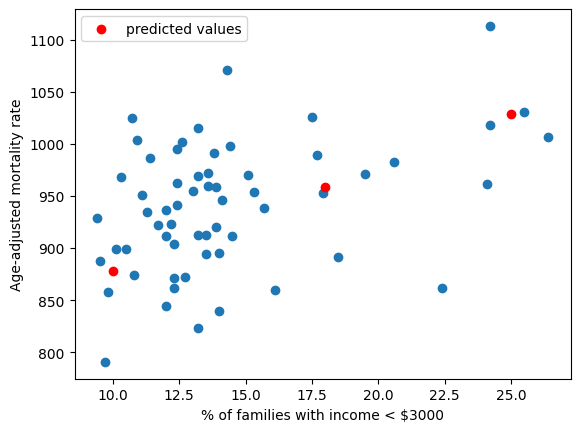

In [29]:
fig,ax = plt.subplots()

ax.scatter(x_obs,y_obs)
ax.scatter(x0,predictions,color='red', label='predicted values')
ax.legend()
ax.set_ylabel('Age-adjusted mortality rate')
ax.set_xlabel('% of families with income < $3000')